## 5 · Baseline models

### By:
Sofía Arango Patiño

### Date:
2026-11-02

### Description:

Fifth step of the proof of concept ([issue #5](https://github.com/modsiw-mona/anomaly_detection_ato/issues/5);
CRISP-DM phase 4, *modelling*; thesis objective **OE3**).

1. **Data** — the development side of the user-level split (issue #4). The test side stays closed until issue #7.
2. **Evaluation protocol** — repeated, user-grouped, stratified cross-validation and metrics built for extreme
   imbalance (development plan, section 5).
3. **Baselines** — a dummy, single-signal rules from the EDA, the **Freeman et al. (2016) RBA score** (the
   established method), and a simple trained model (logistic regression).
4. **Why the established method underperforms here** — a diagnosis of Freeman's score.
5. **Learning curves and scalability** of the trained baseline.
6. **The bar for issue #6**, and recommendations for the real model.

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

# Make the project's `src/` importable, wherever the notebook is opened from.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline

from data.datasets import load_dataset_config
from data.features import feature_columns
from data.intermediate import intermediate_path
from data.split import load_side
from model.baselines import fit_logistic, predict_scores, rule_scores, training_sample
from model.evaluation import assign_folds, bootstrap_pr_auc, evaluate
from model.freeman import HIERARCHY, freeman_terms
from model.preprocessing import build_preprocessor, to_model_frame

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(45)
pl.Config.set_tbl_width_chars(170)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")

## 💾 Load data — development side only

In [3]:
config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
dev = load_side(config, data_dir, "dev").collect()
N_REPEATS, N_FOLDS = 3, 5
folds = assign_folds(dev, n_folds=N_FOLDS, n_repeats=N_REPEATS)
dev = dev.join(folds.drop("has_takeover"), on="user_id").sort("event_id")  # joins do not keep order
y = dev["label_ato"].to_numpy()
fold_of = {r: dev[f"fold_{r}"].to_numpy() for r in range(N_REPEATS)}
print(
    f"development side: {dev.height:,} logins, {int(y.sum())} takeovers, {dev['user_id'].n_unique():,} users"
)
print(f"prevalence: {y.mean():.2e} (one takeover per {1 / y.mean():,.0f} logins)")

development side: 7,868,084 logins, 112 takeovers, 2,215,023 users
prevalence: 1.42e-05 (one takeover per 70,251 logins)


The train/test split was made in issue #4 (`data/05_model_input/rba_split.parquet`): a random 20% of users,
grouped by user and stratified by label. Everything here uses the development side; within it, models are trained
and validated with cross-validation.

## 📏 Evaluation protocol

**Folds.** 5 folds × 3 repeats = 15 validation folds. **Grouped by user** — all logins of a user fall in the same
fold, so a model never meets in validation a user it learnt in training — and **stratified at user level**, so each
fold gets ~22 takeovers:

In [4]:
(
    dev.group_by("fold_0")
    .agg(
        pl.col("user_id").n_unique().alias("users"),
        pl.len().alias("logins"),
        pl.col("label_ato").sum().alias("takeovers"),
    )
    .sort("fold_0")
)

fold_0,users,logins,takeovers
i8,u32,u32,u32
0,443005,1572971,22
1,443005,1564558,23
2,443005,1582884,23
3,443004,1569312,22
4,443004,1578359,22


**Metrics.** Accuracy is useless at one takeover per 70,000 logins: answering "legitimate" always scores
99.999%. Instead:

| Metric | Meaning | Chance level |
| --- | --- | --- |
| **PR-AUC** (primary) | Average precision over all thresholds | the prevalence, 1.4 × 10⁻⁵ |
| **Recall @ 0.1% / 1%** | Share of takeovers caught if the top 0.1% / 1% of logins is reviewed (an *alert budget*) | 0.1% / 1% |
| **Precision @ 1%** | Share of flagged logins that are takeovers — a *lower bound*, since unconfirmed takeovers may hide among the "legitimate" | the prevalence |
| **Friction @ 1%** | Share of legitimate logins challenged at that budget | ≈ 1% |
| ROC-AUC | Ranking quality overall (secondary: optimistic under imbalance) | 0.5 |

Rules produce many tied scores, so budget metrics use the **expected value under random tie-breaking** instead of an
arbitrary order. Results are reported as **mean ± std across the 15 folds**, plus a **bootstrap 95% interval** for
PR-AUC that resamples the takeovers (the scarce class) on out-of-fold scores.

## 🧱 Baselines

| Baseline | Score | Trained? |
| --- | --- | --- |
| Dummy | the same for every login | no |
| Rule: new country | 1 if the user never succeeded from this country before | no |
| Rule: attack IP | 1 if the IP is on attacker lists | no |
| Rule: new country + attack IP | 0, 1 or 2 | no |
| **Freeman RBA score** | Freeman et al. (2016): global over local likelihood of IP and user-agent values, with the reference implementation's weights for this dataset (`src/model/freeman.py`) | no |
| Logistic regression | default features (issue #4), balanced class weights, trained on all takeovers + 5% of legitimate logins | yes |

A user's **first** login has no history: "new country" and Freeman's score are undefined there. As in the reference
implementation (which only scores later logins), these baselines never flag a first login. The logistic regression
sees the `first_success` flag and global features, so it can.

### Scores

In [5]:
start = time.perf_counter()
terms = freeman_terms(pl.scan_parquet(intermediate_path(config, data_dir)), config).collect()
dev = dev.join(terms, on="event_id", how="left").sort("event_id")
ratio = sum(dev[f"log_global_{f}"] - dev[f"log_local_{f}"] for f in HIERARCHY)
freeman = (dev["log_prior"] + ratio).fill_null(-1e9).to_numpy()  # unscored first logins rank last
print(f"Freeman terms for {terms.height:,} logins in {time.perf_counter() - start:.0f} s")

scores = {name: [s] * N_REPEATS for name, s in rule_scores(dev).items()}
scores["Freeman RBA score"] = [freeman] * N_REPEATS

start, fit_seconds = time.perf_counter(), []
logistic = []
for r in range(N_REPEATS):
    oof = np.empty(dev.height)
    for k in range(N_FOLDS):
        in_fold = fold_of[r] == k
        tick = time.perf_counter()
        model = fit_logistic(dev.filter(pl.Series(~in_fold)))
        fit_seconds.append(time.perf_counter() - tick)
        oof[in_fold] = predict_scores(model, dev.filter(pl.Series(in_fold)))
    logistic.append(oof)
scores["logistic regression"] = logistic
print(
    f"logistic regression: {N_REPEATS * N_FOLDS} fits, {np.mean(fit_seconds):.1f} s each, "
    f"{time.perf_counter() - start:.0f} s in total"
)

Freeman terms for 12,541,438 logins in 9 s


logistic regression: 15 fits, 1.6 s each, 38 s in total


### Cross-validation results

In [6]:
METRICS = [
    "pr_auc",
    "recall_at_0_1pct",
    "recall_at_1pct",
    "precision_at_1pct",
    "friction_at_1pct",
    "roc_auc",
]


def cross_validate(mask: np.ndarray) -> pl.DataFrame:
    rows = [
        {"model": name, "repeat": r, "fold": k, **evaluate(y[m], per_repeat[r][m])}
        for name, per_repeat in scores.items()
        for r in range(N_REPEATS)
        for k in range(N_FOLDS)
        if (m := mask & (fold_of[r] == k)).any()
    ]
    return pl.DataFrame(rows)


def summary(per_fold: pl.DataFrame) -> pl.DataFrame:
    return per_fold.group_by("model", maintain_order=True).agg(
        *(
            pl.format("{} ± {}", pl.col(m).mean().round(4), pl.col(m).std().round(4)).alias(m)
            for m in METRICS
        )
    )


all_logins = np.ones(dev.height, dtype=bool)
per_fold = cross_validate(all_logins)
summary(per_fold)

model,pr_auc,recall_at_0_1pct,recall_at_1pct,precision_at_1pct,friction_at_1pct,roc_auc
str,str,str,str,str,str,str
"""dummy (constant)""","""0.0 ± 0.0""","""0.001 ± 0.0""","""0.01 ± 0.0""","""0.0 ± 0.0""","""0.01 ± 0.0""","""0.5 ± 0.0"""
"""rule: new country""","""0.0007 ± 0.0002""","""0.0894 ± 0.0164""","""0.5029 ± 0.0915""","""0.0007 ± 0.0001""","""0.01 ± 0.0""","""0.7475 ± 0.046"""
"""rule: attack IP""","""0.0001 ± 0.0""","""0.0087 ± 0.0016""","""0.087 ± 0.0163""","""0.0001 ± 0.0""","""0.01 ± 0.0""","""0.7337 ± 0.0505"""
"""rule: new country + attack IP""","""0.0041 ± 0.0024""","""0.3092 ± 0.0952""","""0.3667 ± 0.0884""","""0.0005 ± 0.0001""","""0.01 ± 0.0""","""0.8389 ± 0.0585"""
"""Freeman RBA score""","""0.0003 ± 0.0002""","""0.0534 ± 0.0386""","""0.2151 ± 0.0888""","""0.0003 ± 0.0001""","""0.01 ± 0.0""","""0.591 ± 0.074"""
"""logistic regression""","""0.0426 ± 0.025""","""0.5274 ± 0.1025""","""0.8044 ± 0.0993""","""0.0011 ± 0.0001""","""0.01 ± 0.0""","""0.9593 ± 0.0235"""


**PR-AUC with bootstrap 95% intervals** (out-of-fold scores of the first repeat; every development login is
scored once):

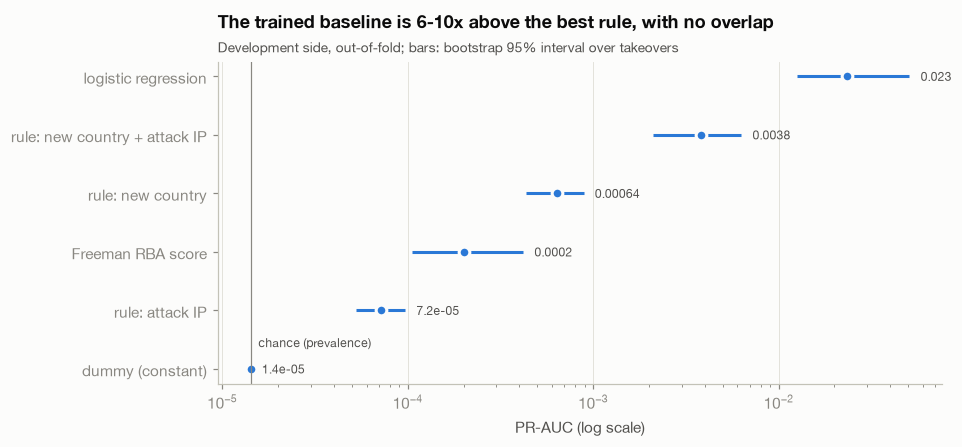

model,pr_auc,low,high
str,f64,f64,f64
"""dummy (constant)""",0.00001,0.00001,0.00001
"""rule: attack IP""",0.00007,0.00005,0.0001
"""Freeman RBA score""",0.0002,0.00011,0.00042
"""rule: new country""",0.00064,0.00044,0.00089
"""rule: new country + attack IP""",0.0038,0.00209,0.00629
"""logistic regression""",0.02328,0.01256,0.05068


In [7]:
rows = []
for name, per_repeat in scores.items():
    low, high = bootstrap_pr_auc(y, per_repeat[0], n_boot=2_000)
    rows.append(
        {
            "model": name,
            "pr_auc": average_precision_score(y, per_repeat[0]),
            "low": low,
            "high": high,
        }
    )
pr = pl.DataFrame(rows).sort("pr_auc")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
yy = np.arange(pr.height)
ax.hlines(yy, pr["low"], pr["high"], color=BLUE, linewidth=2)
ax.plot(pr["pr_auc"], yy, "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.axvline(y.mean(), color=MUTED, linewidth=0.8)
ax.text(y.mean() * 1.1, 0.45, "chance (prevalence)", color=INK_2, fontsize=8, va="center")
for i, value in enumerate(pr["pr_auc"]):
    ax.text(pr["high"][i] * 1.15, i, f"{value:.2g}", color=INK_2, fontsize=8, va="center")
ax.set_xscale("log")
ax.set_yticks(yy, pr["model"])
ax.grid(axis="x")
ax.set_xlabel("PR-AUC (log scale)")
ax.set_title("The trained baseline is 6-10x above the best rule, with no overlap", pad=22)
subtitle(ax, "Development side, out-of-fold; bars: bootstrap 95% interval over takeovers")
plt.show()
pr.with_columns(pl.col("pr_auc", "low", "high").round(5))

The pooled out-of-fold PR-AUC (this chart) is lower than the mean of the per-fold values (table above: 0.043
for the logistic regression) because it ranks together scores from five separately trained models; it is the
conservative of the two estimates. Either way, the trained baseline's interval lies entirely above the best
rule's.

### On logins with history only

Freeman's score and the "new country" rule are designed for users with history. Restricted to those logins
(first logins excluded), each baseline is measured on its own ground:

In [8]:
has_history = ~dev["first_success"].to_numpy()
summary(cross_validate(has_history))

model,pr_auc,recall_at_0_1pct,recall_at_1pct,precision_at_1pct,friction_at_1pct,roc_auc
str,str,str,str,str,str,str
"""dummy (constant)""","""0.0 ± 0.0""","""0.001 ± 0.0""","""0.01 ± 0.0""","""0.0 ± 0.0""","""0.01 ± 0.0""","""0.5 ± 0.0"""
"""rule: new country""","""0.001 ± 0.0003""","""0.1015 ± 0.0128""","""0.7918 ± 0.0987""","""0.001 ± 0.0002""","""0.01 ± 0.0""","""0.8918 ± 0.0494"""
"""rule: attack IP""","""0.0001 ± 0.0""","""0.0112 ± 0.0026""","""0.1122 ± 0.0255""","""0.0001 ± 0.0""","""0.01 ± 0.0""","""0.7386 ± 0.0605"""
"""rule: new country + attack IP""","""0.0062 ± 0.003""","""0.4824 ± 0.1169""","""0.5428 ± 0.1067""","""0.0007 ± 0.0002""","""0.01 ± 0.0""","""0.9039 ± 0.0517"""
"""Freeman RBA score""","""0.0005 ± 0.0002""","""0.0523 ± 0.0343""","""0.3213 ± 0.1136""","""0.0004 ± 0.0002""","""0.01 ± 0.0""","""0.7921 ± 0.0693"""
"""logistic regression""","""0.0664 ± 0.043""","""0.6087 ± 0.1285""","""0.8025 ± 0.11""","""0.001 ± 0.0002""","""0.01 ± 0.0""","""0.962 ± 0.0291"""


## 🔬 Why does the established method underperform here?

Freeman's score is the product of two parts: how unusual the value is **for the user** (the local likelihood
p(x|u), in the denominator) and how common it is **globally** (p(x), in the numerator). The global factor encodes
an assumption: an attacker is more likely to arrive from *popular* values. Four variants, on logins with history,
separate the parts (each removes or flips one ingredient):

In [9]:
local = sum(dev[f"log_local_{f}"] for f in HIERARCHY)
glob = sum(dev[f"log_global_{f}"] for f in HIERARCHY)
variants = {
    "Freeman as published": dev["log_prior"] + glob - local,
    "without the user prior": glob - local,
    "without the global factor (novelty only)": -local,
    "global rarity adds risk": -glob - local,
}
rows = []
for name, score in variants.items():
    s = score.fill_null(-1e9).to_numpy()
    folds_metrics = [
        evaluate(y[m], s[m])
        for r in range(N_REPEATS)
        for k in range(N_FOLDS)
        if (m := has_history & (fold_of[r] == k)).any()
    ]
    rows.append(
        {
            "variant (logins with history)": name,
            **{
                m: f"{np.mean([f[m] for f in folds_metrics]):.4f} ± {np.std([f[m] for f in folds_metrics], ddof=1):.4f}"
                for m in ("pr_auc", "recall_at_1pct", "roc_auc")
            },
        }
    )
pl.DataFrame(rows)

variant (logins with history),pr_auc,recall_at_1pct,roc_auc
str,str,str,str
"""Freeman as published""","""0.0005 ± 0.0002""","""0.3213 ± 0.1136""","""0.7921 ± 0.0693"""
"""without the user prior""","""0.0006 ± 0.0005""","""0.3911 ± 0.1017""","""0.8131 ± 0.0717"""
"""without the global factor (novelty only)""","""0.0033 ± 0.0009""","""0.7793 ± 0.1045""","""0.9127 ± 0.0474"""
"""global rarity adds risk""","""0.0030 ± 0.0008""","""0.8229 ± 0.1048""","""0.9324 ± 0.0402"""


Removing the global factor **doubles** recall at a 1% budget, and making rarity *add* risk improves it further.
The reason is in the EDA: here **takeovers come from globally rare values** — a takeover's country had 0.14% of all
earlier logins versus 65% for a legitimate one. Freeman's numerator rewards popular values, so it *lowers* the
risk of exactly these logins. The weakness is the model's assumption about attackers, not the implementation:
attackers in this service did not blend into popular networks. This points the real model towards **novelty for
the user combined with global rarity**.

## ⚖️ How imbalance is handled matters more than the model

The logistic regression trains on every takeover plus 5% of legitimate logins. Two ways to weight that sample, on
the 5 folds of the first repeat:

In [10]:
cols = feature_columns()
rows = []
for name, class_weight, inverse in (
    ("weights restore real proportions", None, True),
    ("balanced class weights", "balanced", False),
):
    values = []
    for k in range(N_FOLDS):
        in_fold = fold_of[0] == k
        sample = training_sample(dev.filter(pl.Series(~in_fold)))
        pipe = Pipeline(
            [
                ("preprocess", build_preprocessor(cols)),
                ("model", LogisticRegression(max_iter=2_000, class_weight=class_weight)),
            ]
        )
        weight = np.where(sample["label_ato"].to_numpy(), 1.0, 1 / 0.05) if inverse else None
        pipe.fit(
            to_model_frame(sample, cols),
            sample["label_ato"].to_numpy(),
            model__sample_weight=weight,
        )
        values.append(evaluate(y[in_fold], predict_scores(pipe, dev.filter(pl.Series(in_fold)))))
    rows.append(
        {
            "weighting": name,
            **{
                m: f"{np.mean([v[m] for v in values]):.4f} ± {np.std([v[m] for v in values], ddof=1):.4f}"
                for m in ("pr_auc", "recall_at_1pct")
            },
        }
    )
pl.DataFrame(rows)

weighting,pr_auc,recall_at_1pct
str,str,str
"""weights restore real proportions""","""0.0001 ± 0.0001""","""0.1063 ± 0.0663"""
"""balanced class weights""","""0.0327 ± 0.0153""","""0.8051 ± 0.0877"""


Restoring the real proportions (≈1 takeover per 70,000 logins) lets the L2 penalty wash out the ~90 training
takeovers, and the model falls below the rules. Balanced weights keep them visible. This is consistent with recent
work favouring class weights and threshold choice over resampling (Elor & Averbuch-Elor, 2022; van den Goorbergh et
al., 2022) — and it is why issue #6 compares imbalance strategies explicitly.

## 📈 Learning curve

Validation PR-AUC as the training set grows (share of training **users**, stratified; 5 folds of the first
repeat). Training PR-AUC is measured on all training logins of the sampled users:

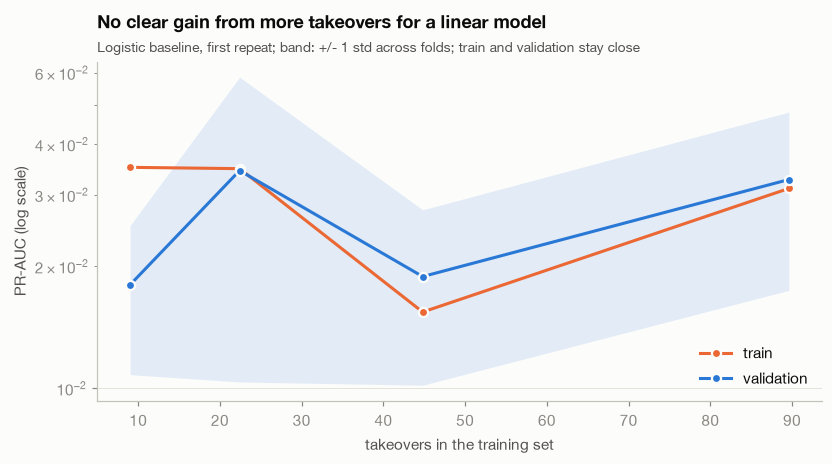

share,training takeovers,training rows (sampled),train,validation,validation std,fit s,predict s per M rows
f64,f64,f64,f64,f64,f64,f64,f64
0.1,9.0,31482.0,0.035,0.018,0.0072,0.13,0.65
0.25,22.4,78827.8,0.0348,0.0344,0.024,0.39,0.61
0.5,44.8,157331.6,0.0154,0.0189,0.0087,0.84,0.62
1.0,89.6,314808.6,0.0311,0.0327,0.0153,1.76,0.57


In [11]:
SHARES = [0.1, 0.25, 0.5, 1.0]
rng = np.random.default_rng(20261102)
rows = []
for k in range(N_FOLDS):
    in_fold = fold_of[0] == k
    train_all, val = dev.filter(pl.Series(~in_fold)), dev.filter(pl.Series(in_fold))
    users = (
        train_all.group_by("user_id").agg(pl.col("label_ato").any().alias("pos")).sort("user_id")
    )
    for share in SHARES:
        keep = []
        for flag in (True, False):
            ids = users.filter(pl.col("pos") == flag)["user_id"].to_numpy()
            keep.append(rng.choice(ids, size=max(1, round(share * ids.size)), replace=False))
        train = train_all.filter(pl.col("user_id").is_in(np.concatenate(keep)))
        tick = time.perf_counter()
        model = fit_logistic(train)
        fit_s = time.perf_counter() - tick
        tick = time.perf_counter()
        val_scores = predict_scores(model, val)
        predict_s = time.perf_counter() - tick
        rows.append(
            {
                "fold": k,
                "share": share,
                "training takeovers": int(train["label_ato"].sum()),
                "training rows (sampled)": int(
                    train["label_ato"].sum() + round(0.05 * (~train["label_ato"]).sum())
                ),
                "train pr_auc": average_precision_score(
                    train["label_ato"].to_numpy(), predict_scores(model, train)
                ),
                "validation pr_auc": average_precision_score(y[in_fold], val_scores),
                "fit s": fit_s,
                "predict s per M rows": predict_s / val.height * 1e6,
            }
        )
curve = (
    pl.DataFrame(rows)
    .group_by("share")
    .agg(
        pl.col("training takeovers").mean(),
        pl.col("training rows (sampled)").mean(),
        pl.col("train pr_auc").mean().alias("train"),
        pl.col("validation pr_auc").mean().alias("validation"),
        pl.col("validation pr_auc").std().alias("validation std"),
        pl.col("fit s").mean(),
        pl.col("predict s per M rows").mean(),
    )
    .sort("share")
)

fig, ax = plt.subplots(figsize=(8.5, 4))
for column, color in (("train", ORANGE), ("validation", BLUE)):
    ax.plot(
        curve["training takeovers"],
        curve[column],
        "o-",
        color=color,
        label=column,
        markersize=6,
        markeredgecolor=SURFACE,
        markeredgewidth=1.5,
    )
ax.fill_between(
    curve["training takeovers"],
    curve["validation"] - curve["validation std"],
    curve["validation"] + curve["validation std"],
    color=BLUE,
    alpha=0.12,
    linewidth=0,
)
ax.set_yscale("log")
ax.grid(axis="y")
ax.legend(loc="lower right")
ax.set_xlabel("takeovers in the training set")
ax.set_ylabel("PR-AUC (log scale)")
ax.set_title("No clear gain from more takeovers for a linear model", pad=22)
subtitle(
    ax,
    "Logistic baseline, first repeat; band: +/- 1 std across folds; train and validation stay close",
)
plt.show()
curve.with_columns(
    pl.col("train", "validation", "validation std").round(4),
    pl.col("fit s", "predict s per M rows").round(2),
)

Validation PR-AUC moves between about 0.02 and 0.04 with no trend, inside a wide fold-to-fold band, and
**training and validation stay close**: the linear model is not overfitting. Its limit is **capacity** — a linear
combination of the features cannot capture more — rather than the number of labelled takeovers. More labels would
not clearly help *this* model; a more expressive one is the next step.

## ⏱️ Scalability

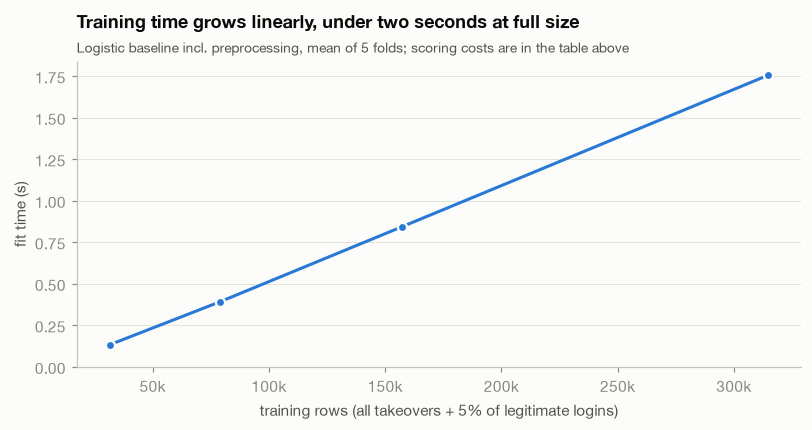

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(
    curve["training rows (sampled)"],
    curve["fit s"],
    "o-",
    color=BLUE,
    markersize=6,
    markeredgecolor=SURFACE,
    markeredgewidth=1.5,
)
ax.grid(axis="y")
ax.set_ylim(0, None)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
ax.set_xlabel("training rows (all takeovers + 5% of legitimate logins)")
ax.set_ylabel("fit time (s)")
ax.set_title("Training time grows linearly, under two seconds at full size", pad=22)
subtitle(
    ax,
    "Logistic baseline incl. preprocessing, mean of 5 folds; scoring costs are in the table above",
)
plt.show()

Training cost is negligible thanks to sampling the legitimate logins (all takeovers are kept) — under two
seconds at full size — and scoring runs at under a second per million logins, so the full dataset is no problem
on a laptop. Training without sampling
would multiply the rows by ~20 for little expected gain.

## 🎯 The bar for issue #6

The anteproyecto's question 7 (notebook 1) left the operating target to be fixed once a baseline existed:

- **Bar to beat:** the logistic regression — pooled out-of-fold PR-AUC 0.023 (95% interval 0.013 – 0.050) and
  recall 0.80 ± 0.10 at a 1% alert budget. A candidate should clear the upper end of that interval at equal or
  better recall (friction is ≈1% by construction).
- **Reference points:** the best rule ("new country + attack IP") and Freeman's score as published, which every
  candidate must clearly exceed.

## 🧭 Recommendations for the real model (issue #6)

1. **Combine novelty for the user with global rarity** — the diagnosis above shows this is where the signal is,
   and the opposite of Freeman's assumption. The feature table already contains both families; tree ensembles can
   learn their interaction.
2. **Handle imbalance with class weights and threshold choice**, and compare against undersampling and SMOTE
   explicitly (the anteproyecto mentions SMOTE).
3. **Address the cold start** (39% of takeovers on a first login) with the global features; report results on
   first logins separately.
4. **Gradient-boosted trees** (XGBoost / LightGBM) and an unsupervised detector (Isolation Forest) are the next
   candidates, plus the hybrid (anomaly scores as features) and PU bagging from the plan.
5. **Ablations** decide the artefact flags, RTT, geography and time features.
6. The learning curve shows the linear baseline is **capacity-limited, not data-limited**: more expressive models
   are the priority. With 112 takeovers, fold-to-fold variance is large, so every comparison must carry its
   interval.

## 📊 Analysis of Results and Conclusions

- **The protocol works at this level of imbalance**: user-grouped, stratified folds give each validation fold ~22
  takeovers; budget metrics handle ties; the takeover bootstrap gives honest intervals.
- **The trained baseline wins clearly.** Logistic regression on the issue #4 features reaches 6 to 10 times the
  PR-AUC of the best rule (pooled 0.023 vs 0.0038, intervals not overlapping; per-fold mean 0.043 vs 0.0041) and
  far above Freeman's score, with recall around 80% at a 1% alert budget — but with wide variation across folds,
  as expected with ~22 takeovers per fold.
- **The established RBA score underperforms**, and the diagnosis explains why: its global factor assumes attackers
  use popular values, while takeovers here come from globally rare ones. Removing or flipping that factor doubles its
  recall. This is a substantive finding for the thesis, not an implementation artefact — though the implementation is
  documented as a simplification of the reference.
- **How imbalance is handled matters more than the model**: weighting the sample back to the true proportions ruins
  the logistic regression; balanced weights fix it.
- **The linear baseline is limited by capacity, not by data** (flat learning curve, train close to validation),
  and **cost is not a constraint** (training under two seconds, scoring under a second per million logins).

## 💡 Proposals and Ideas

- Issue #6: model-family comparison with the recommendations above, against the bar fixed here; ablations; tuning of
  the best two or three; the chosen pipeline saved as `.joblib`.
- Report results separately for first logins and logins with history in every later comparison.
- Thesis text: the Freeman diagnosis is worth its own discussion — the assumption about attacker behaviour is
  testable, and it fails on this service.

## 📖 References

- Freeman, D., Jain, S., Dürmuth, M., Biggio, B., & Giacinto, G. (2016). Who Are You? A Statistical Approach to
  Measuring User Authenticity. *NDSS*. https://doi.org/10.14722/ndss.2016.23240
- Wiefling, S., Jørgensen, P. R., Thunem, S., & Lo Iacono, L. (2022). Pump Up Password Security! *ACM TOPS*, 26(1).
  https://doi.org/10.1145/3546069 — and the reference implementation `das-group/rba-algorithm`.
- Elor, Y., & Averbuch-Elor, H. (2022). To SMOTE, or not to SMOTE? arXiv:2201.08528.
- van den Goorbergh, R., van Smeden, M., Timmerman, D., & Van Calster, B. (2022). The harm of class imbalance
  corrections for risk prediction models. *JAMIA*, 29(9).
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating
  binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3).
- Course methodology — baseline model: https://joserzapata.github.io/post/ciencia-datos-proyecto-python/5-baseline_model/